# Experiment 1: Adversarial Chain Scaling & Pointer-Hop Counter

## Aim
Build all five connectivity engines (**V1 to V5**) and run them on the worst-case **chain** input for
`n = 500, 1000, 2000, 5000`. For every version we measure:

- build time and query time
- average pointer hops per query and per Find
- the maximum tree depth after the build
- peak memory

Then we check the two claims from the handout:

- **V4** (union by rank) never gets deeper than `floor(log2 n)`.
- **V5** (path compression) needs fewer than **1.5** hops per query on average.

## 1. Import the required libraries

- `random` picks the query targets, using a fixed seed so every run is the same.
- `time`, `statistics`, `gc` and `tracemalloc` are used for timing and memory.
- `deque` is the queue for the BFS in V1.
- `ABC` and `abstractmethod` define the shared interface.
- `csv` and `os` save the results, and `matplotlib.pyplot` draws the graphs.

In [ ]:
import csv
import gc
import math
import os
import random
import statistics
import time
import tracemalloc
from abc import ABC, abstractmethod
from collections import deque

import matplotlib.pyplot as plt

## 2. How pointer hops are counted

Each version has a `hops` counter. We count one "hop" every time the structure does one step of
searching:

| Version | What counts as one hop |
|---|---|
| V1 | one vertex taken out of the BFS queue |
| V2 | nothing, because `id[x]` is a direct lookup (always 0) |
| V3, V4, V5 | one parent pointer followed inside `find` |

For V5 we only count the first loop of `find` (walking up to the root). The second loop rewires
pointers to the root, so it is cleanup, not searching.

## 3. Shared interface

All five versions share one interface, so the experiment code can treat them the same way.

- `Connectivity` is the base for everything: `union(u, v)`, `connected(u, v)`, a `hops` counter and
  `reset_hops()`.
- `DisjointSet` adds `find(x)` and answers `connected(u, v)` as `find(u) == find(v)`.

V1 only uses `Connectivity`, because a BFS graph has no `find`. V2 to V5 use `DisjointSet`.

In [ ]:
class Connectivity(ABC):

    def __init__(self, n):
        self.n = n
        self.hops = 0

    def reset_hops(self):
        self.hops = 0

    @abstractmethod
    def union(self, u, v):
        """Connect u and v. Returns False if nothing new was merged."""

    @abstractmethod
    def connected(self, u, v):
        """True if u and v are in the same group."""


class DisjointSet(Connectivity):

    @abstractmethod
    def find(self, x):
        """Root (representative) of x's group."""

    def connected(self, u, v):
        return self.find(u) == self.find(v)

## 4. The five versions

### V1: Adjacency list + BFS

- `union(u, v)` adds the edge to both adjacency lists in O(1).
- `connected(u, v)` runs a fresh BFS from `u` and stops as soon as it reaches `v`.
- **Bottleneck:** every query can visit the whole graph, so one query costs O(n + e).

`union` only returns `False` for `u == v`. Knowing whether two vertices were already connected would
need a BFS for every union, which would make the build O(n²).

In [3]:
class AdjacencyBFS(Connectivity):

    def __init__(self, n):
        super().__init__(n)
        self.adj = [[] for _ in range(n)]

    def union(self, u, v):
        if u == v:
            return False
        self.adj[u].append(v)
        self.adj[v].append(u)
        return True

    def connected(self, u, v):
        seen = [False] * self.n
        seen[u] = True
        queue = deque([u])

        while queue:
            x = queue.popleft()
            self.hops += 1

            # Stop early once we reach v
            if x == v:
                return True

            for y in self.adj[x]:
                if not seen[y]:
                    seen[y] = True
                    queue.append(y)

        return False

### V2: Quick-Find (`id[]` array)

- `id[i]` stores the group number of element `i`, so `find(x)` is just `id[x]`.
- `union(u, v)` changes every entry equal to `id[u]` into `id[v]`.
- **Bottleneck:** every union scans the whole array, so `n - 1` unions cost O(n²).

In [4]:
class QuickFind(DisjointSet):

    def __init__(self, n):
        super().__init__(n)
        self.id = list(range(n))

    def find(self, x):
        # Direct lookup, so no hops
        return self.id[x]

    def union(self, u, v):
        old_id = self.id[u]
        new_id = self.id[v]

        if old_id == new_id:
            return False

        # Scan the whole array: this is the O(n) part
        for i in range(self.n):
            if self.id[i] == old_id:
                self.id[i] = new_id

        return True

### Shared up-tree code for V3, V4 and V5

V3, V4 and V5 all store a `parent[]` array, so this part is written once in `UpTree`:

- `find(x)` follows parent pointers up to the root. It uses a `while` loop, not recursion, because
  V3's tree can be 4999 levels deep and recursion would crash.
- `depth(x)` walks up the same way but **does not count hops or change anything**. That way measuring
  the depth of V5 does not compress its tree.
- `max_depth()` is the largest depth of any node.

In [5]:
class UpTree(DisjointSet):

    def __init__(self, n):
        super().__init__(n)
        self.parent = list(range(n))

    def find(self, x):
        while x != self.parent[x]:
            x = self.parent[x]
            self.hops += 1
        return x

    def depth(self, x):
        d = 0
        while x != self.parent[x]:
            x = self.parent[x]
            d += 1
        return d

    def max_depth(self):
        deepest = 0
        for x in range(self.n):
            deepest = max(deepest, self.depth(x))
        return deepest

### V3: Naive up-trees

- `union(u, v)` sets `parent[find(u)] = find(v)` without looking at tree heights.
- **Bottleneck:** a bad union order can build one long "stick", so `find` takes O(n) hops.

In [6]:
class NaiveUpTree(UpTree):

    def union(self, u, v):
        ru = self.find(u)
        rv = self.find(v)

        if ru == rv:
            return False

        # No rank check: u's tree always goes under v's root
        self.parent[ru] = rv
        return True

### V4: Union by rank

- `rank[r]` is an upper bound on the height of the tree with root `r`.
- The shorter tree always goes under the taller one.
- On a tie we use the handout's rule: `parent[rv] = ru` and `rank[ru] += 1`.
- **Guarantee:** a tree of rank `k` has at least `2^k` nodes, so the height is at most `floor(log2 n)`.

In [7]:
class UnionByRank(UpTree):

    def __init__(self, n):
        super().__init__(n)
        self.rank = [0] * n

    def union(self, u, v):
        ru = self.find(u)
        rv = self.find(v)

        if ru == rv:
            return False

        if self.rank[ru] < self.rank[rv]:
            self.parent[ru] = rv

        elif self.rank[ru] > self.rank[rv]:
            self.parent[rv] = ru

        else:
            # Tie: v's root goes under u's root, and u's root gets one level taller
            self.parent[rv] = ru
            self.rank[ru] += 1

        return True

### V5: Union by rank + path compression

V5 is V4 with a new `find`. This is the handout's two-pass `find_compressed`:

1. Walk up to find the root.
2. Walk the same path again and point every node on it straight at the root.

Later finds on those nodes then take only 1 hop.

In [8]:
class PathCompression(UnionByRank):

    def find(self, x):
        # First pass: find the root
        root = x
        while root != self.parent[root]:
            root = self.parent[root]
            self.hops += 1

        # Second pass: point every node on the path at the root
        while x != root:
            nxt = self.parent[x]
            self.parent[x] = root
            x = nxt

        return root


VERSIONS = {
    "V1": AdjacencyBFS,
    "V2": QuickFind,
    "V3": NaiveUpTree,
    "V4": UnionByRank,
    "V5": PathCompression,
}

## 5. Inputs

### Adversarial chain

`union(0, 1), union(1, 2), ..., union(n-2, n-1)`

- **V3 becomes a stick.** Before `union(i, i+1)`, the root of the whole chain is `i`. The union puts
  that root under the new node `i + 1`, so the tree grows one level every time. Node 0 ends up
  `n - 1` hops from the root.
- **V4 stays flat.** After `union(0, 1)`, root 0 has rank 1. Every later node is a rank-0 singleton,
  so it always goes directly under 0. The depth stays 1.

### Binomial input

The chain keeps V4 at depth 1, so it cannot show that the `log2 n` bound is **tight**. The binomial
input unions in rounds: pairs, then groups of 4, then groups of 8, and so on (`n` must be a power of 2).
Every union in a round is a tie in rank, so the height grows by exactly one each round and ends at
`log2 n`.

### Query targets

Each query is `connected(0, j)` with a random `j`. Node 0 is the deepest node in V3's stick. The same
`j` values are used for every version, so all versions answer the same questions.

In [9]:
SEED = 42
CHAIN_SIZES = [500, 1000, 2000, 5000]
BINOMIAL_SIZES = [512, 1024, 2048, 4096]   # Powers of 2, close to the chain sizes
TIMING_RUNS = 3


def floor_log2(n):
    # Exact integer version of floor(log2(n))
    return n.bit_length() - 1


def build_chain(ds, n):
    for i in range(n - 1):
        ds.union(i, i + 1)


def build_binomial(ds, n):
    if n & (n - 1) != 0:
        raise ValueError("binomial input needs n to be a power of 2")

    size = 1
    while size < n:
        for start in range(0, n, 2 * size):
            ds.union(start, start + size)
        size = size * 2


def make_targets(n):
    rng = random.Random(SEED)
    return [rng.randrange(n) for _ in range(n)]


def run_queries(ds, targets):
    for j in targets:
        ds.connected(0, j)

## 6. Correctness checks

Before measuring anything, we check that the code is correct:

1. **All versions agree.** 1,000 random streams of unions and queries on `n = 50`. Every version must
   give the same `connected` answer as V1 (BFS is the ground truth).
2. **V3 chain is a stick:** max depth is `n - 1`.
3. **V4 depth bound:** at most `floor(log2 n)` on both inputs, and exactly `floor(log2 n)` on binomial.
4. **V5 hops:** fewer than 1.5 hops per query on the chain.
5. **Hand traces from Part A:**
   - `n = 6` chain: V3 `parent = [1,2,3,4,5,5]`; V4 `parent = [0,0,0,0,0,0]`, `rank = [1,0,0,0,0,0]`
   - `n = 8` rounds: V4 `parent = [0,0,0,2,0,4,4,6]`, `rank = [3,0,1,0,2,0,1,0]`
   - After one V5 `find(7)`: `parent = [0,0,0,2,0,4,0,0]`

In [10]:
def build_rounds_of_8(ds):
    for u, v in [(0, 1), (2, 3), (4, 5), (6, 7), (0, 2), (4, 6), (0, 4)]:
        ds.union(u, v)


# 1. All versions agree with BFS on random streams
rng = random.Random(SEED)
n = 50
for stream in range(1000):
    engines = {name: make(n) for name, make in VERSIONS.items()}
    for step in range(100):
        u = rng.randrange(n)
        v = rng.randrange(n)
        if rng.random() < 0.3:
            for ds in engines.values():
                ds.union(u, v)
        else:
            truth = engines["V1"].connected(u, v)
            for name, ds in engines.items():
                assert ds.connected(u, v) == truth, f"{name} wrong on stream {stream}"
print("Random streams: all 5 versions agree")

# 2. V3 chain is a stick
for n in [2, 10, 100, 1000]:
    ds = NaiveUpTree(n)
    build_chain(ds, n)
    assert ds.max_depth() == n - 1
print("V3 chain depth == n - 1")

# 3. V4 depth bound on both inputs
for n in [2, 10, 100, 1000, 5000]:
    ds = UnionByRank(n)
    build_chain(ds, n)
    assert ds.max_depth() <= floor_log2(n)
for n in [2, 8, 64, 1024, 4096]:
    ds = UnionByRank(n)
    build_binomial(ds, n)
    assert ds.max_depth() == floor_log2(n)
print("V4 depth <= floor(log2 n), and == on binomial")

# 4. V5 hops on the chain
for n in CHAIN_SIZES:
    ds = PathCompression(n)
    build_chain(ds, n)
    ds.reset_hops()
    targets = make_targets(n)
    run_queries(ds, targets)
    assert ds.hops / len(targets) < 1.5
print("V5 avg hops per query < 1.5")

# 5. Hand traces
ds = NaiveUpTree(6)
build_chain(ds, 6)
assert ds.parent == [1, 2, 3, 4, 5, 5]

ds = UnionByRank(6)
build_chain(ds, 6)
assert ds.parent == [0, 0, 0, 0, 0, 0]
assert ds.rank == [1, 0, 0, 0, 0, 0]

ds = UnionByRank(8)
build_rounds_of_8(ds)
assert ds.parent == [0, 0, 0, 2, 0, 4, 4, 6]
assert ds.rank == [3, 0, 1, 0, 2, 0, 1, 0]

ds = PathCompression(8)
build_rounds_of_8(ds)
ds.reset_hops()
assert ds.find(7) == 0
assert ds.hops == 3   # 7 -> 6 -> 4 -> 0
assert ds.parent == [0, 0, 0, 2, 0, 4, 0, 0]
print("Hand traces match Part A")

print("All checks passed!")

Random streams: all 5 versions agree
V3 chain depth == n - 1
V4 depth <= floor(log2 n), and == on binomial
V5 avg hops per query < 1.5
Hand traces match Part A
All checks passed!


## 7. Measurement functions

Each (version, n) pair is measured in three separate parts:

- **Hops and depth:** build once, measure the max depth, reset hops, run the queries.
  Hops per query counts both finds in `connected`, so hops per Find is half of that (V2 to V5 only).
- **Time:** build and query, timed with `time.perf_counter()`. We do 3 runs and keep the **median**.
  Garbage collection is turned off during each timed run so a random GC pause does not slow down
  only one version.
- **Memory:** a separate run with `tracemalloc`, because tracing makes the code much slower and would
  ruin the timing.

In [11]:
def measure_hops_and_depth(make, n, build, targets):
    ds = make(n)
    build(ds, n)

    depth = None
    if isinstance(ds, UpTree):
        depth = ds.max_depth()

    # Only count hops during the query phase
    ds.reset_hops()
    run_queries(ds, targets)

    hops_per_query = ds.hops / len(targets)
    hops_per_find = None
    if isinstance(ds, DisjointSet):
        hops_per_find = ds.hops / (2 * len(targets))

    return depth, hops_per_query, hops_per_find


def time_once(make, n, build, targets):
    ds = make(n)
    gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        build(ds, n)
        t1 = time.perf_counter()
        run_queries(ds, targets)
        t2 = time.perf_counter()
    finally:
        gc.enable()
    return t1 - t0, t2 - t1


def measure_times(make, n, build, targets):
    build_times = []
    query_times = []
    for run in range(TIMING_RUNS):
        b, q = time_once(make, n, build, targets)
        build_times.append(b)
        query_times.append(q)
    return statistics.median(build_times), statistics.median(query_times)


def measure_peak_memory(make, n, build, targets):
    # The targets list was made before tracing starts, so it is not counted
    gc.collect()
    tracemalloc.start()
    ds = make(n)
    build(ds, n)
    run_queries(ds, targets)
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak


def measure_row(input_name, version, n, build, targets):
    make = VERSIONS[version]
    depth, hops_per_query, hops_per_find = measure_hops_and_depth(make, n, build, targets)
    build_s, query_s = measure_times(make, n, build, targets)
    peak = measure_peak_memory(make, n, build, targets)

    return {
        "input": input_name,
        "version": version,
        "n": n,
        "build_time_s": build_s,
        "query_time_s": query_s,
        "total_time_s": build_s + query_s,
        "avg_hops_per_query": hops_per_query,
        "avg_hops_per_find": hops_per_find,
        "max_depth": depth,
        "floor_log2_n": floor_log2(n),
        "peak_memory_bytes": peak,
    }

## 8. Run the experiment

- **Chain:** all five versions for every `n` in `CHAIN_SIZES`.
- **Binomial:** V4 and V5 for every `n` in `BINOMIAL_SIZES`. This shows that V4's bound is tight,
  and it is also where V5's path compression actually lowers the hop count (on the chain V4 is already
  flat, so V4 and V5 look the same).

This takes about 1 to 2 minutes. Most of that time is V1 and V2 at `n = 5000`.

In [12]:
rows = []

for n in CHAIN_SIZES:
    targets = make_targets(n)
    print("Chain, n =", n)
    for version in VERSIONS:
        row = measure_row("chain", version, n, build_chain, targets)
        rows.append(row)
        print("   ", version, "query time =", round(row["query_time_s"], 4), "s,",
              "hops/query =", round(row["avg_hops_per_query"], 2))

for n in BINOMIAL_SIZES:
    targets = make_targets(n)
    print("Binomial, n =", n)
    for version in ["V4", "V5"]:
        row = measure_row("binomial", version, n, build_binomial, targets)
        rows.append(row)
        print("   ", version, "max depth =", row["max_depth"],
              "(floor log2 n =", str(row["floor_log2_n"]) + "),",
              "hops/query =", round(row["avg_hops_per_query"], 2))

print("Experiment completed!")

Chain, n = 500


    V1 query time = 0.0144 s, hops/query = 242.73
    V2 query time = 0.0 s, hops/query = 0.0


    V3 query time = 0.0151 s, hops/query = 756.27
    V4 query time = 0.0001 s, hops/query = 1.0
    V5 query time = 0.0001 s, hops/query = 1.0
Chain, n = 1000


    V1 query time = 0.0535 s, hops/query = 501.92


    V2 query time = 0.0001 s, hops/query = 0.0


    V3 query time = 0.0573 s, hops/query = 1497.08
    V4 query time = 0.0001 s, hops/query = 1.0
    V5 query time = 0.0002 s, hops/query = 1.0
Chain, n = 2000


... (5 outputs left out)

    V3 query time = 1.4133 s, hops/query = 7469.38
    V4 query time = 0.0006 s, hops/query = 1.0
    V5 query time = 0.001 s, hops/query = 1.0
Binomial, n = 512


    V4 max depth = 9 (floor log2 n = 9), hops/query = 4.46
    V5 max depth = 9 (floor log2 n = 9), hops/query = 1.75
Binomial, n = 1024
    V4 max depth = 10 (floor log2 n = 10), hops/query = 4.97


    V5 max depth = 10 (floor log2 n = 10), hops/query = 1.77
Binomial, n = 2048
    V4 max depth = 11 (floor log2 n = 11), hops/query = 5.52
    V5 max depth = 11 (floor log2 n = 11), hops/query = 1.78
Binomial, n = 4096


    V4 max depth = 12 (floor log2 n = 12), hops/query = 6.01
    V5 max depth = 12 (floor log2 n = 12), hops/query = 1.77
Experiment completed!


## 9. Save the results to CSV

The results are written to `results/exp1.csv` and then read back. All plots and the summary use the
CSV, so they always match the saved file. Empty values (for example, depth for V1 and V2) are saved
as blank cells.

In [13]:
FIELDS = [
    "input", "version", "n",
    "build_time_s", "query_time_s", "total_time_s",
    "avg_hops_per_query", "avg_hops_per_find",
    "max_depth", "floor_log2_n", "peak_memory_bytes",
]

os.makedirs("results", exist_ok=True)
with open("results/exp1.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=FIELDS)
    writer.writeheader()
    writer.writerows(rows)


def number_or_none(text, kind):
    if text == "":
        return None
    return kind(text)


results = []
with open("results/exp1.csv", newline="") as f:
    for raw in csv.DictReader(f):
        results.append({
            "input": raw["input"],
            "version": raw["version"],
            "n": int(raw["n"]),
            "build_time_s": float(raw["build_time_s"]),
            "query_time_s": float(raw["query_time_s"]),
            "total_time_s": float(raw["total_time_s"]),
            "avg_hops_per_query": float(raw["avg_hops_per_query"]),
            "avg_hops_per_find": number_or_none(raw["avg_hops_per_find"], float),
            "max_depth": number_or_none(raw["max_depth"], int),
            "floor_log2_n": int(raw["floor_log2_n"]),
            "peak_memory_bytes": int(raw["peak_memory_bytes"]),
        })

print("Saved and reloaded", len(results), "rows from results/exp1.csv")

Saved and reloaded 28 rows from results/exp1.csv


## 10. Plot the results

Five graphs are saved to `figures/`. All use log-log axes, because the versions differ by several
orders of magnitude.

1. **Query runtime vs n** for all five versions.
2. **Total runtime (build + queries) vs n** for all five versions. This is the graph that shows V2's
   cost, because V2 spends all its time in the build.
3. **Average hops per query vs n.** Solid lines are the chain; dotted lines are V4 and V5 on the
   binomial input, where path compression makes a visible difference. V2 is left out because it is
   always 0, and 0 cannot be drawn on a log axis.
4. **Max depth vs n** for V3, V4 and V5, with V4 on the binomial input and a `log2(n)` reference line.
5. **Peak memory vs n** for all five versions.

V4 and V5 give the same numbers on the chain, so they use different markers and V5 is dashed.
Otherwise V4's line would be hidden under V5's.

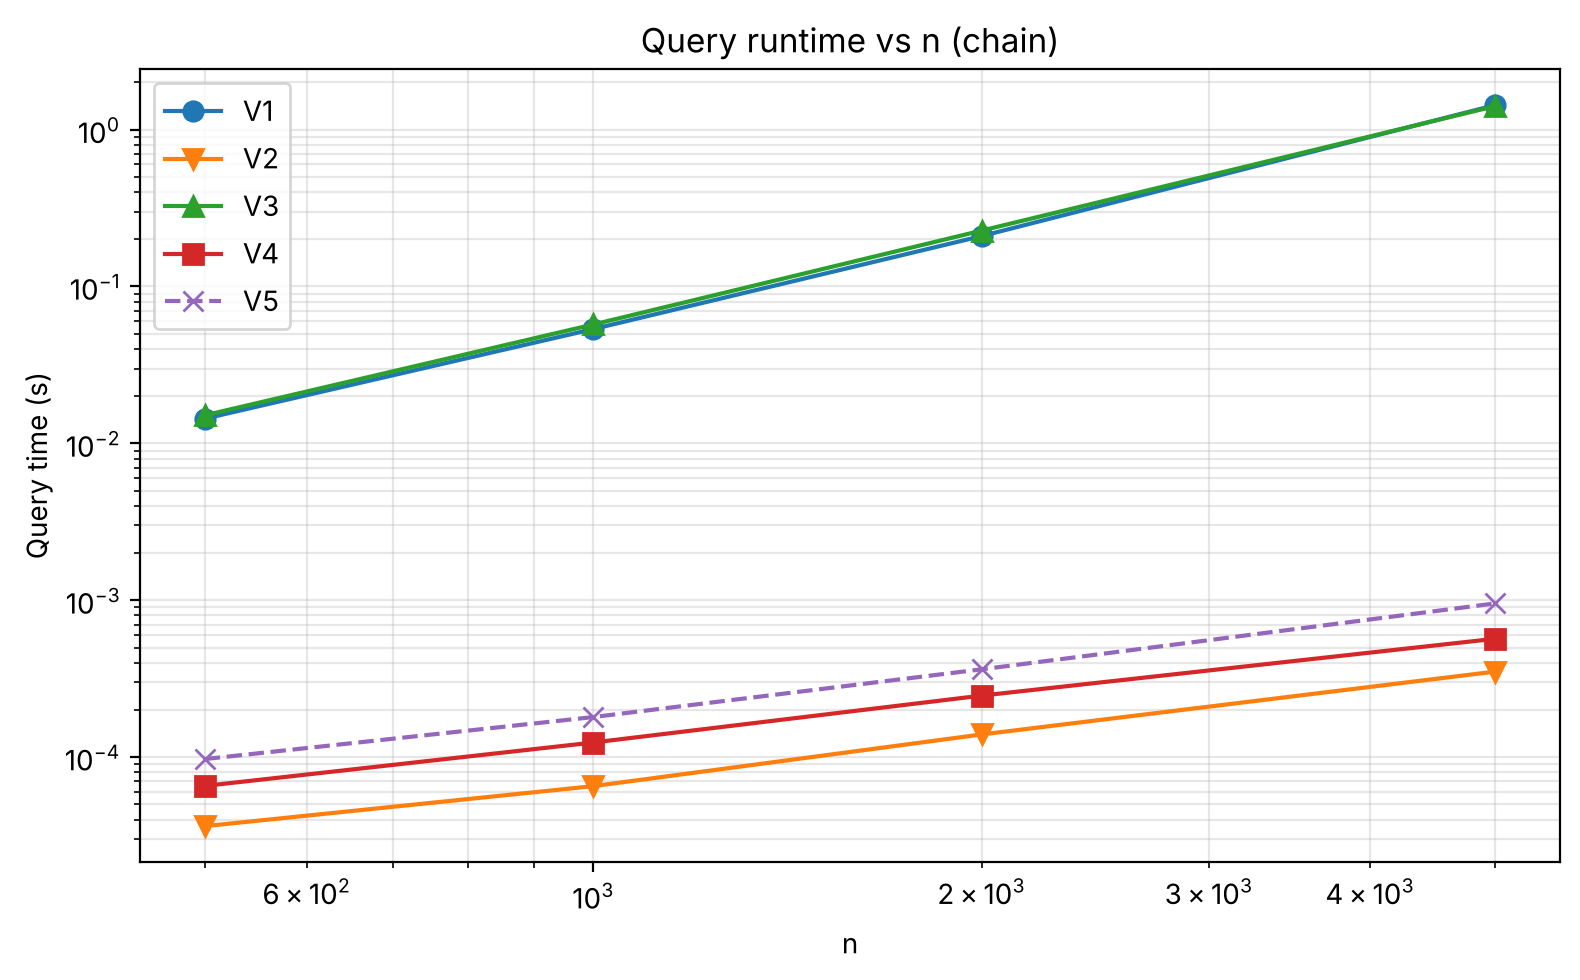

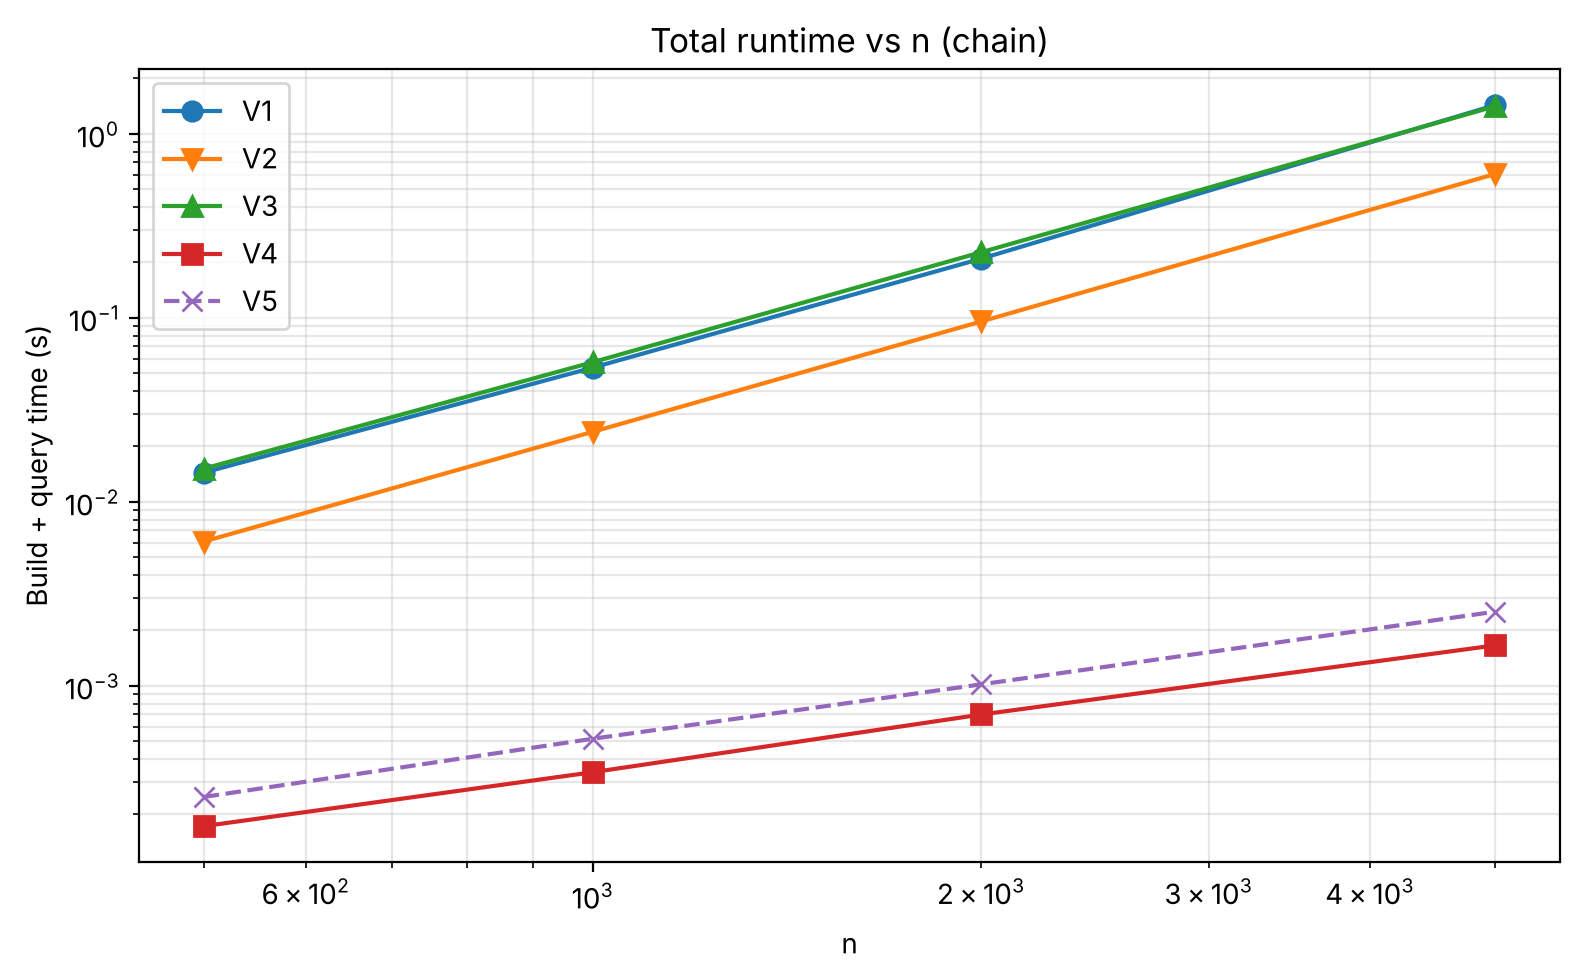

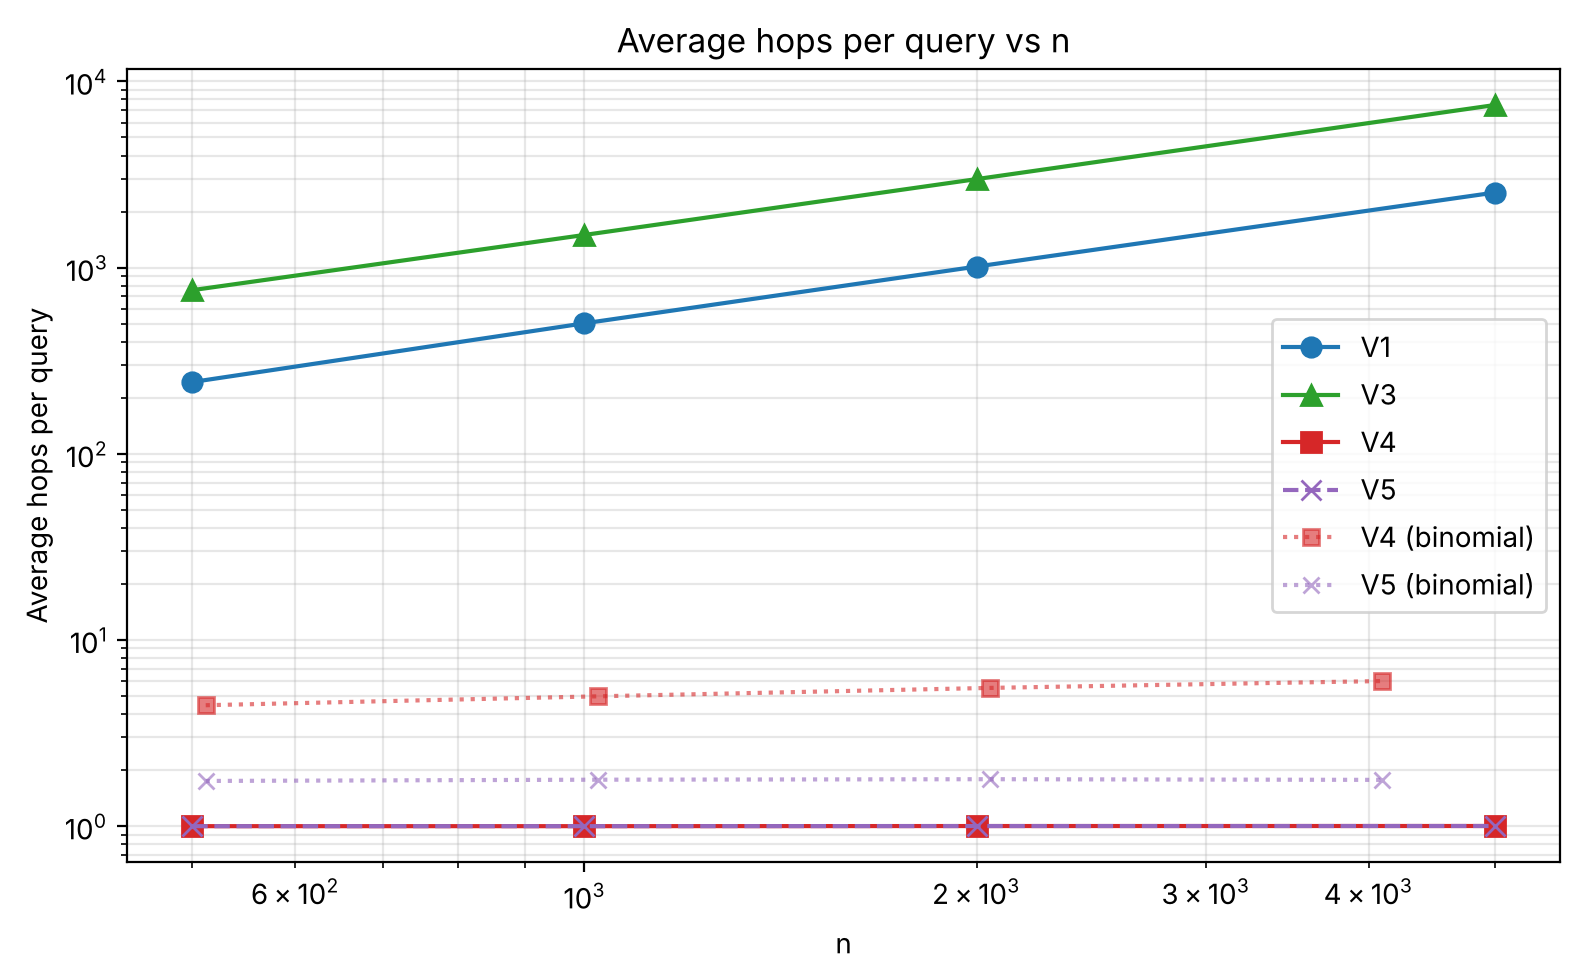

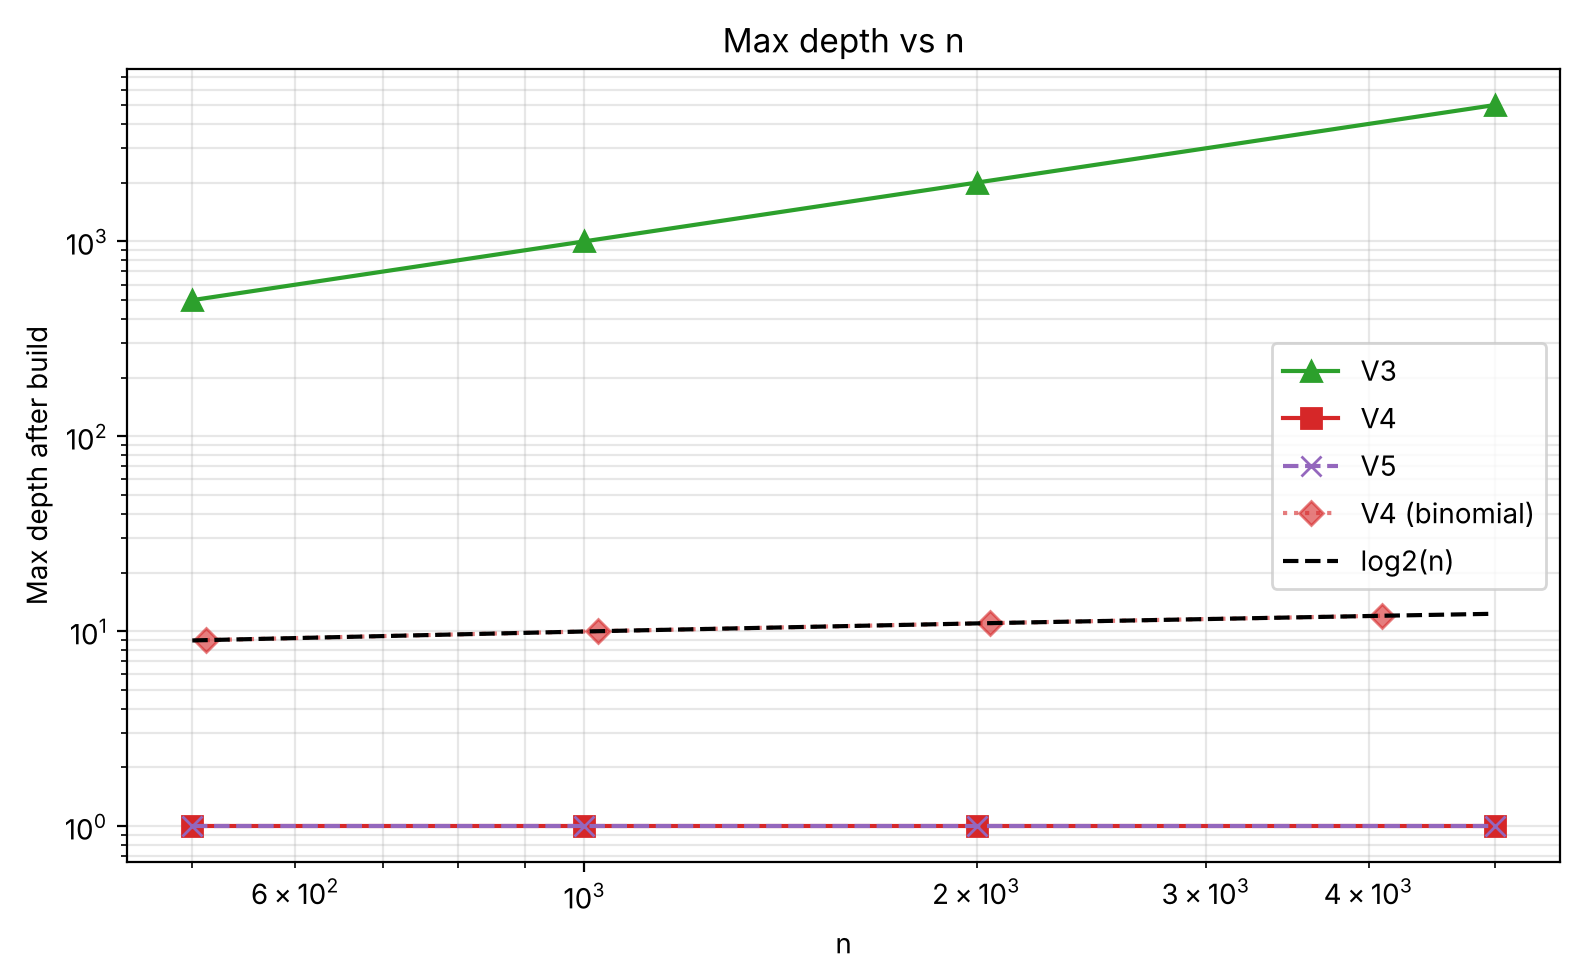

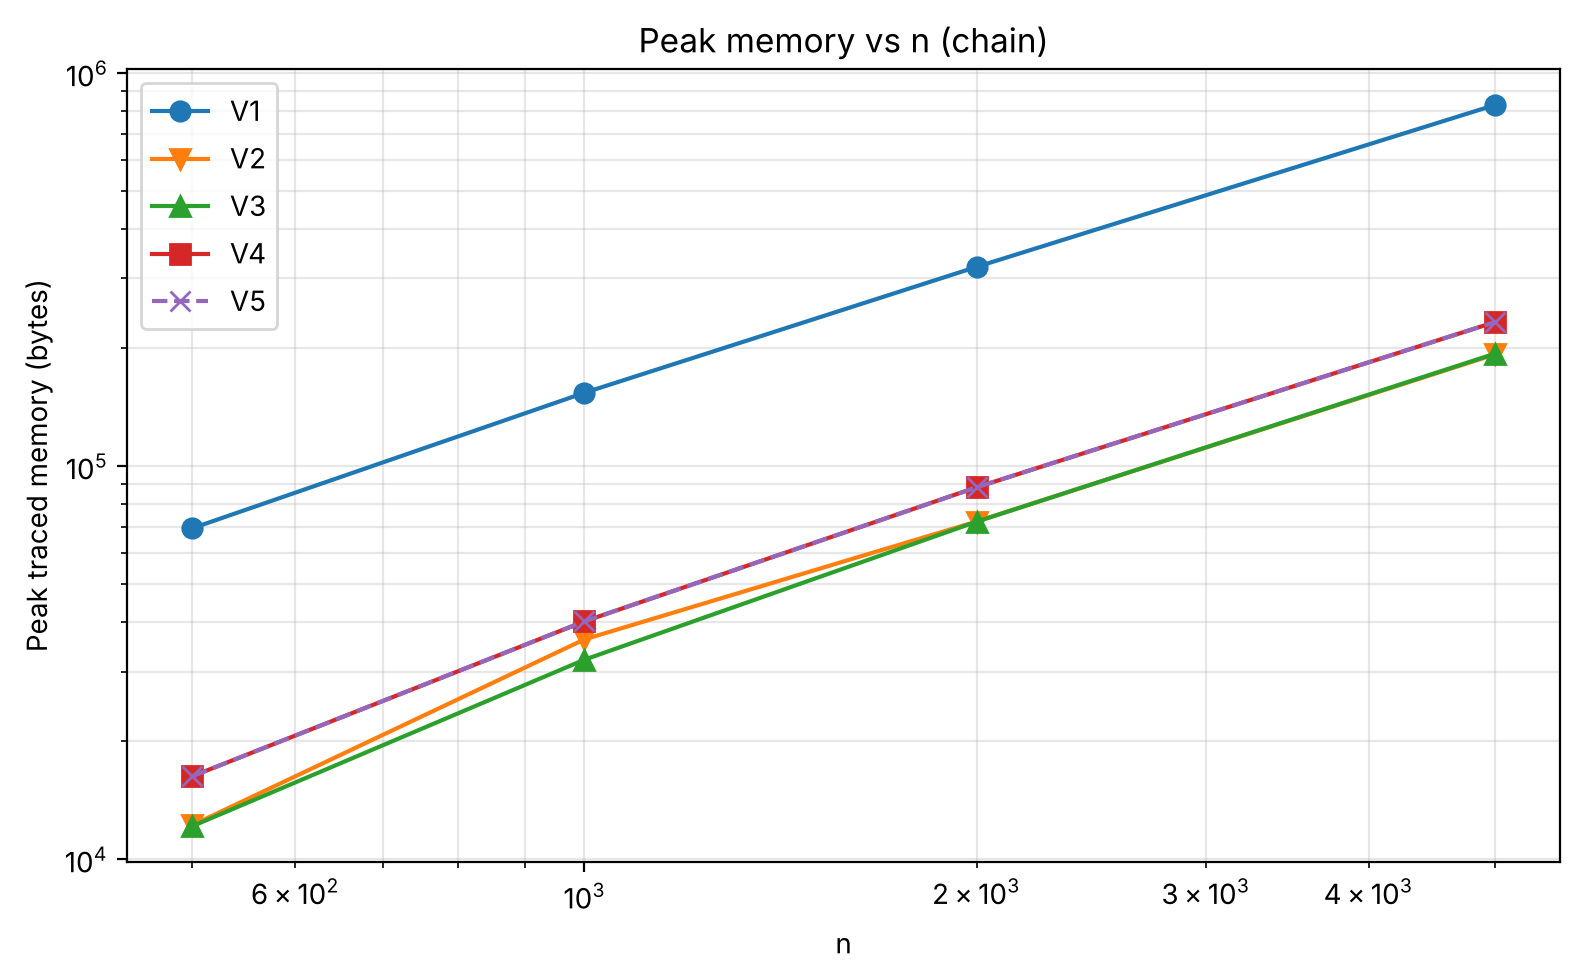

In [14]:
MARKERS = {"V1": "o", "V2": "v", "V3": "^", "V4": "s", "V5": "x"}
LINESTYLES = {"V1": "-", "V2": "-", "V3": "-", "V4": "-", "V5": "--"}
# Same colour for a version in every graph
COLORS = {"V1": "tab:blue", "V2": "tab:orange", "V3": "tab:green", "V4": "tab:red", "V5": "tab:purple"}

os.makedirs("figures", exist_ok=True)


def series(input_name, version, key):
    picked = []
    for r in results:
        if r["input"] == input_name and r["version"] == version:
            picked.append(r)
    picked.sort(key=lambda r: r["n"])

    ns = [r["n"] for r in picked]
    values = [r[key] for r in picked]
    return ns, values


def start_plot(versions, key, ylabel, title):
    plt.figure(figsize=(8, 5))
    for version in versions:
        ns, values = series("chain", version, key)
        plt.plot(ns, values, marker=MARKERS[version], markersize=7,
                 linestyle=LINESTYLES[version], color=COLORS[version], label=version)
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("n")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, which="both", alpha=0.3)


def finish_plot(filename):
    plt.legend()
    plt.tight_layout()
    plt.savefig("figures/" + filename, dpi=150)
    plt.show()


ALL_VERSIONS = list(VERSIONS)

# 1. Query runtime
start_plot(ALL_VERSIONS, "query_time_s", "Query time (s)", "Query runtime vs n (chain)")
finish_plot("exp1_query_time.png")

# 2. Total runtime
start_plot(ALL_VERSIONS, "total_time_s", "Build + query time (s)", "Total runtime vs n (chain)")
finish_plot("exp1_total_time.png")

# 3. Hops per query, chain and binomial
start_plot(["V1", "V3", "V4", "V5"], "avg_hops_per_query", "Average hops per query",
           "Average hops per query vs n")
for version in ["V4", "V5"]:
    ns, values = series("binomial", version, "avg_hops_per_query")
    plt.plot(ns, values, marker=MARKERS[version], linestyle=":", color=COLORS[version],
             alpha=0.6, label=version + " (binomial)")
finish_plot("exp1_hops.png")

# 4. Max depth
start_plot(["V3", "V4", "V5"], "max_depth", "Max depth after build", "Max depth vs n")
ns, depths = series("binomial", "V4", "max_depth")
plt.plot(ns, depths, marker="D", linestyle=":", color=COLORS["V4"], alpha=0.6,
         label="V4 (binomial)")
reference_ns = sorted(CHAIN_SIZES + BINOMIAL_SIZES)
plt.plot(reference_ns, [math.log2(n) for n in reference_ns], "k--", label="log2(n)")
finish_plot("exp1_max_depth.png")

# 5. Peak memory
start_plot(ALL_VERSIONS, "peak_memory_bytes", "Peak traced memory (bytes)",
           "Peak memory vs n (chain)")
finish_plot("exp1_memory.png")

## 11. Summary table

The table lists every row from the CSV. Below it we check the two claims from the handout.

In [15]:
def show(value, digits):
    if value is None:
        return "-"
    return str(round(value, digits))


print(f"{'input':<9}{'ver':<5}{'n':>6}{'build_s':>10}{'query_s':>10}{'hops/q':>10}"
      f"{'hops/find':>11}{'depth':>7}{'log2n':>7}{'peak_KB':>10}")

for r in results:
    print(f"{r['input']:<9}{r['version']:<5}{r['n']:>6}"
          f"{r['build_time_s']:>10.4f}{r['query_time_s']:>10.4f}"
          f"{r['avg_hops_per_query']:>10.2f}{show(r['avg_hops_per_find'], 2):>11}"
          f"{show(r['max_depth'], 0):>7}{r['floor_log2_n']:>7}"
          f"{r['peak_memory_bytes'] / 1024:>10.1f}")

v4_rows = [r for r in results if r["version"] == "V4"]
v4_within_bound = all(r["max_depth"] <= r["floor_log2_n"] for r in v4_rows)
v4_tight = all(r["max_depth"] == r["floor_log2_n"] for r in v4_rows if r["input"] == "binomial")
v5_chain = [r for r in results if r["version"] == "V5" and r["input"] == "chain"]
v5_under = all(r["avg_hops_per_query"] < 1.5 for r in v5_chain)

print()
print("V4 depth <= floor(log2 n) on every input: ", v4_within_bound)
print("V4 depth == floor(log2 n) on binomial:    ", v4_tight)
print("V5 avg hops per query < 1.5 on the chain: ", v5_under)

input    ver       n   build_s   query_s    hops/q  hops/find  depth  log2n   peak_KB
chain    V1      500    0.0000    0.0144    242.73          -      -      8      67.8
chain    V2      500    0.0061    0.0000      0.00        0.0      -      8      11.9
chain    V3      500    0.0001    0.0151    756.27     378.13    499      8      11.8
chain    V4      500    0.0001    0.0001      1.00        0.5      1      8      15.9
chain    V5      500    0.0002    0.0001      1.00        0.5      1      8      15.9
chain    V1     1000    0.0001    0.0535    501.92          -      -      9     149.9
chain    V2     1000    0.0240    0.0001      0.00        0.0      -      9      35.4
chain    V3     1000    0.0001    0.0573   1497.08     748.54    999      9      31.4
chain    V4     1000    0.0002    0.0001      1.00        0.5      1      9      39.3
chain    V5     1000    0.0003    0.0002      1.00        0.5      1      9      39.3
chain    V1     2000    0.0002    0.2097   1012.42    

## 12. Observations

Hop counts and depths are exact and are the same on every machine. Exact times depend on the computer,
so we only compare how fast they grow.

**Depth**
- V3's chain is a perfect stick: max depth is exactly `n - 1` (4999 at `n = 5000`).
- V4 and V5 stay at depth 1 on the chain, because every new node goes straight under root 0.
- On the binomial input, V4's depth is exactly `floor(log2 n)` (9, 10, 11, 12), so the handout's bound
  is **tight**: union by rank can be forced that deep, but never deeper.

**Hops**
- V1 dequeues about `n / 2` vertices per query: the BFS walks the chain until it reaches a random `j`.
- V3 needs about `1.5 n` hops per query: `find(0)` climbs the whole stick (`n - 1` hops), and `find(j)`
  climbs about `n / 2` more.
- V4 and V5 need exactly 1.00 hop per query on the chain (0 for the root 0, 1 for `j`), which is below
  the 1.5 target. On the chain V4 is already flat, so path compression has nothing to fix.
- On the binomial input the difference shows: V4 grows with `log n` (about 4.5 to 6 hops per query),
  while V5 stays flat at about 1.8 hops per query (under 1 hop per Find), because each path is
  compressed the first time it is used.

**Runtime: where each refinement overtakes its predecessor**
- V1 and V3 queries are O(n) each, so `n` queries cost O(n²). When `n` grows 2.5x (2000 to 5000),
  their query time grows about 6 to 7x, close to 2.5² ≈ 6.25.
- V2 moves the cost from queries to the build: queries are almost free, but `n - 1` unions each scan
  the whole array, so the build is O(n²). In total time V2 is still about 2x faster than V1.
- V3 is **slower than V2** on this input. The chain is exactly the case naive up-trees cannot handle:
  building is O(1) per union, but every query pays the full stick.
- V4 fixes this. It is several hundred to 1000x faster than V1 to V3 at `n = 5000`, and its time grows almost
  linearly.
- V5 matches V4 on the chain. Its extra second loop makes it slightly slower here, but it cuts hops by
  about 3x on the binomial input, and that gap keeps growing as `n` grows.

**Memory**
- All versions use O(n) memory. V1 uses the most (about 4x the others) because of the adjacency lists
  and the `seen` list each BFS creates. V4 and V5 use a bit more than V3 because of the extra `rank`
  array.